# N136 — budget-matched quarter-rate MPC selection

Stage: **complete**; active arm: —; last reported arrival: —.

Three methods receive the same 91,968 timestamp-ordered frames from 958 highway-annotated clips. Each waits for four real arrivals and then performs exactly one quarter-rate update. MPC chooses an already-received frame; paced uses the newest; uniform chooses one at random. At completion all have 22,992 committed updates and LR sum 5,748. There are no nominal-rate actions, extra floor updates, clip metadata, future-image previews or runtime task labels. Own buffer fill count is operational state, not clip phase.

| Arm | Arrivals | Updates | Physical LR sum | Probe at | Linear accuracy % | Worst-cell % | CE |
|---|---:|---:|---:|---:|---:|---:|---:|
| buffer_mpc | 91,968 | 22,992 | 5,748.00 | 91,968 | **61.127** | 50.440 | 0.717195 |
| paced_latest | 91,968 | 22,992 | 5,748.00 | 91,968 | **61.429** | 50.726 | 0.689456 |
| uniform_buffer | 91,968 | 22,992 | 5,748.00 | 91,968 | **63.339** | 52.713 | 0.713044 |

Probe at 0 is the parent, not a post-training result. Readouts: 12 support-only readers, 7,844 validation queries, every 6,144 arrivals/prefix/endpoint. Both prefixes and full runs proceed without an outcome gate. The primary comparison is MPC minus paced endpoint balanced accuracy; worst-cell/CE and random-buffer comparison are retained. This is one reused highway-only stream/seed, not broad scene-mixed BDD or independent replication.

MPC uses the N135 unlabeled 88-feature ridge and past-only persistence calibration. H2 now spans the next two eligible update epochs; three identity arrivals intervene. Unknown future image context persists. Objective/references are unchanged: reconstruction plus rank/variance deficit penalties. Five-percent exploration varies which buffered frame is selected, never the number or LR of updates. No gradients guide selection; actual SSL updates use gradients/AdamW.

The control API sees only delivered candidate pixels, their already-delivered predecessors and past learner observations. A maximum five-frame pixel memory suffices. Histories continue across clip joins. Nonfinite training aborts after full rollback instead of silently breaking dose equality.

Operational observation/planning/health overhead is measured separately. Sparse copied health audits run AFTER choice every 2,048 arrivals; their extra diagnostic gradient work is charged separately, fully rolled back and never supplied to predictor feedback or decisions. These are not equal-compute arms. One-step audit regret is not a test of H2/task optimality.



In [1]:
from pathlib import Path
import json
from IPython.display import Image, display
RUN=Path('C:\\CAFL-E\\project\\cafl4ds\\outputs\\budgeted-temporal-mpc\\20261103-n136')
print(json.loads((RUN/'status.json').read_text()))


{
  "stage": "complete",
  "running": false,
  "updated": 1793703175.3635468
}

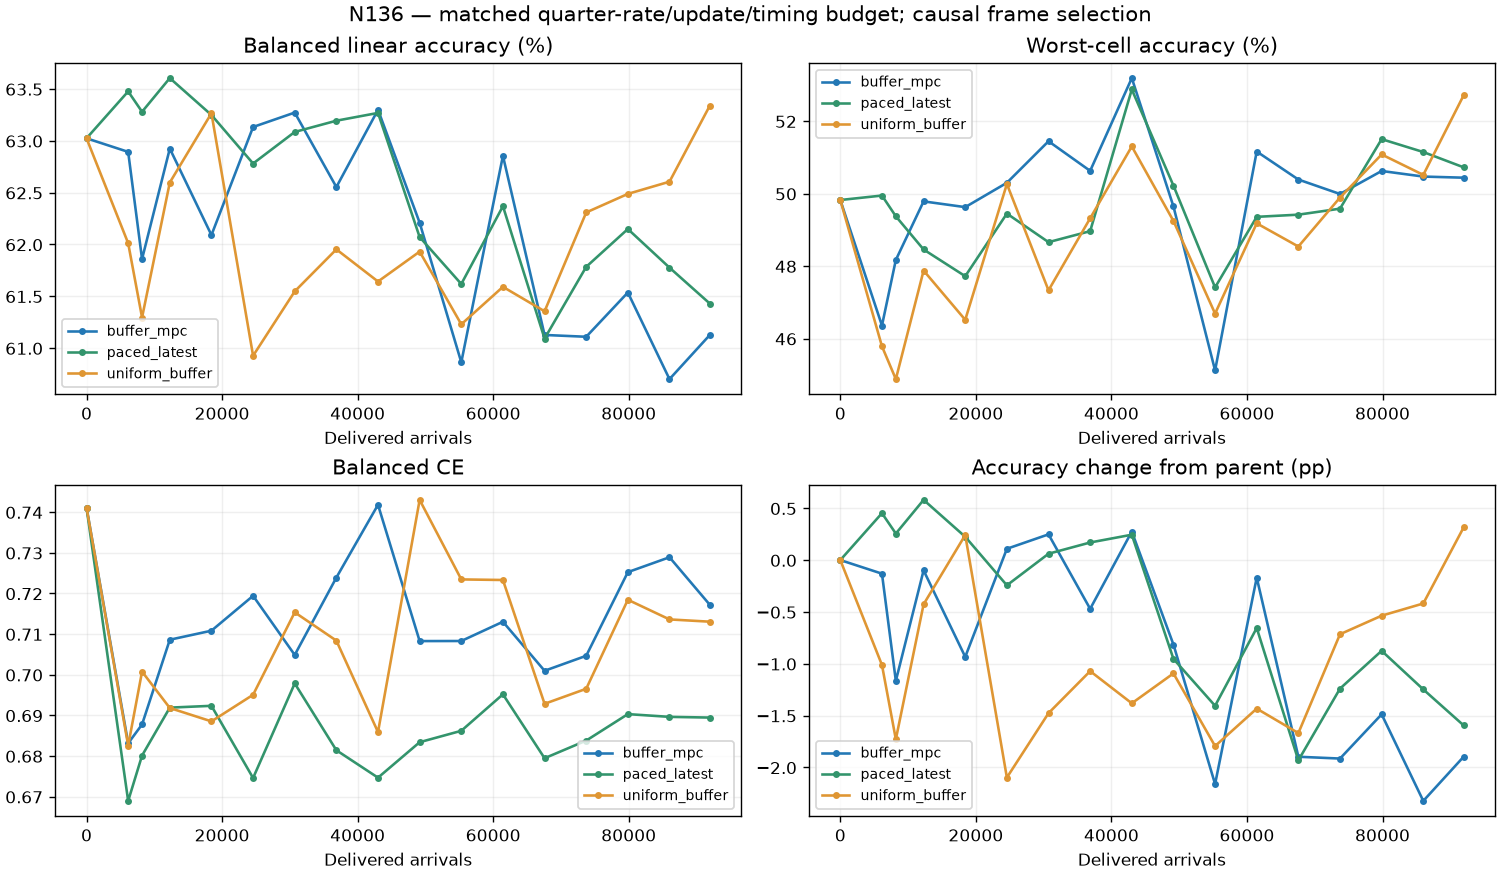

In [2]:
display(Image(filename=str(RUN/'accuracy.png')))


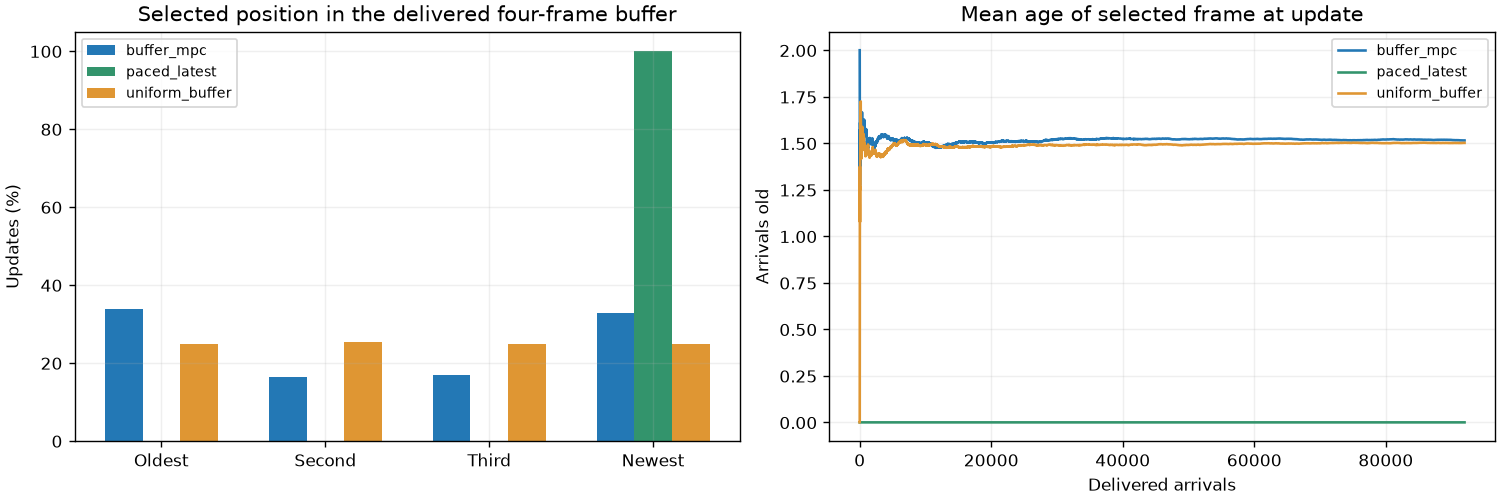

In [3]:
display(Image(filename=str(RUN/'selection.png')))


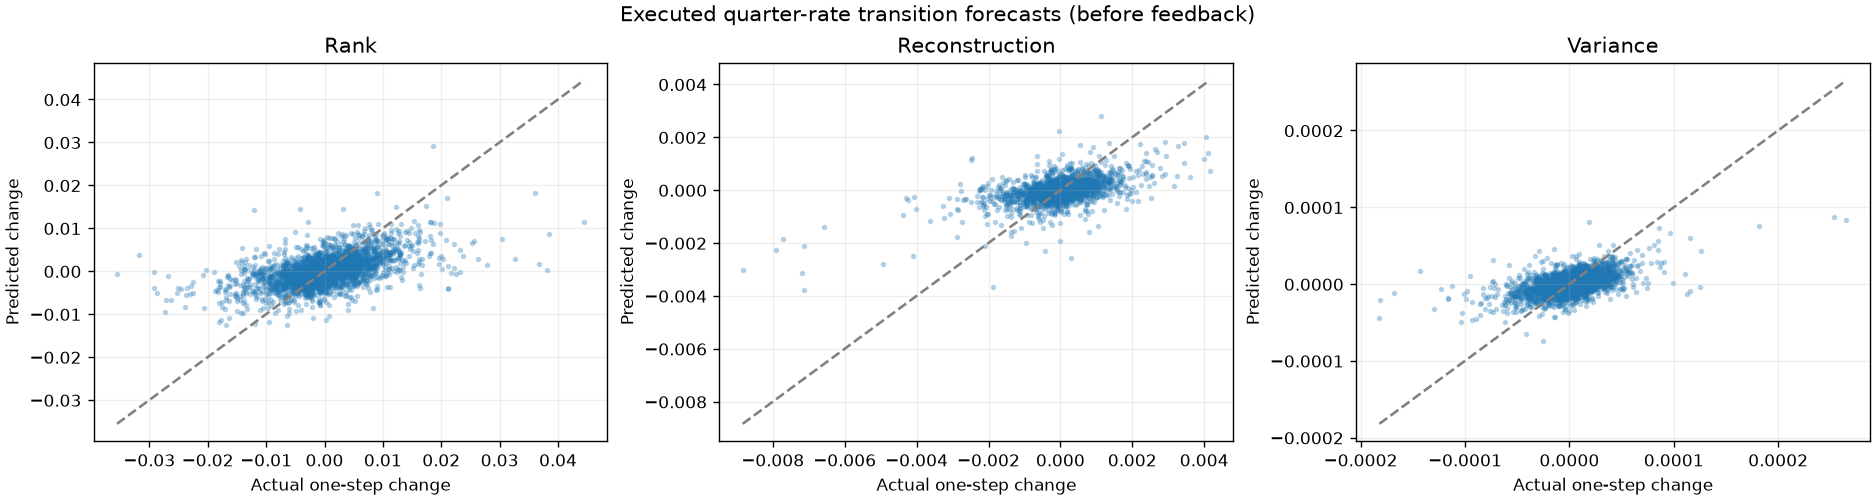

In [4]:
display(Image(filename=str(RUN/'plant.png')))


In [5]:
print(json.dumps(json.loads((RUN/'comparison.json').read_text())['plant'],indent=2))


{
  "n": 22992,
  "persistence_rmse": [
    0.006965954197680107,
    0.0008533505587115148,
    2.6960618120075235e-05
  ],
  "predicted": {
    "rmse": [
      0.005911066936501459,
      0.0007195687096470401,
      2.261558467232428e-05
    ],
    "mse_skill_pct": [
      27.99369504051431,
      28.896728166100814,
      29.63512024253918
    ]
  },
  "raw": {
    "rmse": [
      0.005917949405789421,
      0.0007209412652300736,
      2.2635856380132802e-05
    ],
    "mse_skill_pct": [
      27.825918326324306,
      28.625214773559282,
      29.508919165324098
    ]
  },
  "paired_audit": {
    "decisions": 44,
    "measured_copies": 176,
    "chosen_immediate_j_regret": 0.0001602442646919767,
    "latest_immediate_j_regret": 0.00018441459356558195,
    "uniform_expected_immediate_j_regret": 0.00014197879780291432,
    "chosen_immediate_j_best_fraction": 0.25,
    "all_candidate_mse_skill_pct": [
      21.844832897644505,
      14.440688520119027,
      12.378791851563198
    ]

The notebook is rendered from committed snapshots and refreshes with the live report. Reload to see new saved outputs. Training is unchanged. [Frozen protocol](../../../docs/project-plan/budgeted-temporal-mpc.md). The paced arm must exactly reproduce the N135 paced endpoint and readouts; copied-audit and resume checks are recorded under the run directory.